In [33]:
# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


In [34]:
# ============================================================
# STEP 2: SET FILE PATHS
# ============================================================

INPUT_FILE = r"C:\Users\Aaditya babaso patil\Desktop\SmartPlate_Data_Mining_Project\data\smartplate_cafeteria_cleaned.csv"

OUTPUT_FILE = r"C:\Users\Aaditya babaso patil\Desktop\SmartPlate_Data_Mining_Project\data\smartplate_kmeans_clusters.csv"

print("✅ File paths set successfully")

✅ File paths set successfully


In [35]:
# ============================================================
# STEP 3: LOAD DATASET
# ============================================================

try:
    df = pd.read_csv(INPUT_FILE)

    print("✅ Dataset loaded successfully")
    print("Number of Rows:", df.shape[0])
    print("Number of Columns:", df.shape[1])

except FileNotFoundError:
    print("❌ Dataset file not found")
    print(INPUT_FILE)

✅ Dataset loaded successfully
Number of Rows: 21900
Number of Columns: 19


In [36]:
# ============================================================
# STEP 4: DISPLAY DATASET
# ============================================================

print("First 5 Rows:")

display(df.head())

First 5 Rows:


,Date,Day_of_Week,Food_Item,Food_Category,Meal_Type,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,Weather,Temperature,Special_Event_Flag,Holiday_Flag,Food_Cost_Per_Unit,Selling_Price_Per_Unit,Estimated_Cost_of_Waste,Unmet_Demand,Stockout_Flag
0,2025-01-01,Wednesday,Buttermilk,Beverage,Beverages,41.07,39.09,1.98,39.09,171.55,Cloudy,21.2,1.0,1.0,0.8,1.5,1.58,0.0,0.0
1,2025-01-01,Wednesday,Coffee,Beverage,Beverages,41.47,40.10,1.37,40.10,171.55,Cloudy,21.2,1.0,1.0,0.8,1.5,1.09,0.0,0.0
2,2025-01-01,Wednesday,Lemon Juice,Beverage,Beverages,40.15,37.21,2.94,37.21,171.55,Cloudy,21.2,1.0,1.0,1.0,2.0,2.94,0.0,0.0
3,2025-01-01,Wednesday,Tea,Beverage,Beverages,77.84,57.53,20.31,57.53,171.55,Cloudy,21.2,1.0,1.0,0.5,1.0,10.15,0.0,0.0
4,2025-01-01,Wednesday,Aloo Paratha,Main Course,Breakfast,40.98,39.88,1.10,39.88,171.55,Cloudy,21.2,1.0,1.0,3.0,5.0,3.31,0.0,0.0


In [37]:
# ============================================================
# STEP 5: CHECK COLUMN NAMES
# ============================================================

print("Dataset Columns:")

for number, column in enumerate(df.columns, start=1):
    print(f"{number:02d}. {column}")

Dataset Columns:
01. Date
02. Day_of_Week
03. Food_Item
04. Food_Category
05. Meal_Type
06. Quantity_Prepared
07. Quantity_Sold
08. Quantity_Wasted
09. Actual_Demand
10. Number_of_Students
11. Weather
12. Temperature
13. Special_Event_Flag
14. Holiday_Flag
15. Food_Cost_Per_Unit
16. Selling_Price_Per_Unit
17. Estimated_Cost_of_Waste
18. Unmet_Demand
19. Stockout_Flag


In [38]:
# ============================================================
# STEP 6: SELECT FEATURES
# ============================================================

features = [
    "Quantity_Prepared",
    "Quantity_Sold",
    "Quantity_Wasted",
    "Actual_Demand",
    "Number_of_Students",
    "Temperature",
    "Estimated_Cost_of_Waste",
    "Unmet_Demand"
]

print("Selected Features:")

for feature in features:
    print("✅", feature)

Selected Features:
✅ Quantity_Prepared
✅ Quantity_Sold
✅ Quantity_Wasted
✅ Actual_Demand
✅ Number_of_Students
✅ Temperature
✅ Estimated_Cost_of_Waste
✅ Unmet_Demand


In [39]:
# ============================================================
# STEP 7: CHECK REQUIRED FEATURES
# ============================================================

missing_features = [
    feature
    for feature in features
    if feature not in df.columns
]

if missing_features:

    print("❌ Missing Features:")
    print(missing_features)

else:

    print("✅ All required features are available")

✅ All required features are available


In [40]:
# ============================================================
# STEP 8: CREATE FEATURE DATA
# ============================================================

X = df[features].copy()

print("Feature Dataset Shape:")
print(X.shape)

display(X.head())

Feature Dataset Shape:
(21900, 8)


,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,Temperature,Estimated_Cost_of_Waste,Unmet_Demand
0,41.07,39.09,1.98,39.09,171.55,21.2,1.58,0.0
1,41.47,40.10,1.37,40.10,171.55,21.2,1.09,0.0
2,40.15,37.21,2.94,37.21,171.55,21.2,2.94,0.0
3,77.84,57.53,20.31,57.53,171.55,21.2,10.15,0.0
4,40.98,39.88,1.10,39.88,171.55,21.2,3.31,0.0


In [41]:
# ============================================================
# STEP 9: CHECK MISSING VALUES
# ============================================================

print("Missing Values:")

display(X.isnull().sum())

Missing Values:


Quantity_Prepared          0
Quantity_Sold              0
Quantity_Wasted            0
Actual_Demand              0
Number_of_Students         0
Temperature                0
Estimated_Cost_of_Waste    0
Unmet_Demand               0
dtype: int64

In [42]:
# ============================================================
# STEP 10: HANDLE MISSING VALUES
# ============================================================

X = X.fillna(X.median())

print("✅ Missing values handled")

display(X.isnull().sum())

✅ Missing values handled


Quantity_Prepared          0
Quantity_Sold              0
Quantity_Wasted            0
Actual_Demand              0
Number_of_Students         0
Temperature                0
Estimated_Cost_of_Waste    0
Unmet_Demand               0
dtype: int64

In [43]:
# ============================================================
# STEP 11: STANDARDIZE FEATURES
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("✅ Features standardized successfully")

print("Scaled Data Shape:")
print(X_scaled.shape)

✅ Features standardized successfully
Scaled Data Shape:
(21900, 8)


In [44]:
# ============================================================
# STEP 12: ELBOW METHOD
# ============================================================

inertia = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

    print(
        f"K = {k} | "
        f"Inertia = {model.inertia_:.2f}"
    )

K = 2 | Inertia = 107292.94


K = 3 | Inertia = 88496.71
K = 4 | Inertia = 71282.80
K = 5 | Inertia = 61639.83
K = 6 | Inertia = 54666.84
K = 7 | Inertia = 48528.30
K = 8 | Inertia = 43911.29
K = 9 | Inertia = 40882.11
K = 10 | Inertia = 37893.49


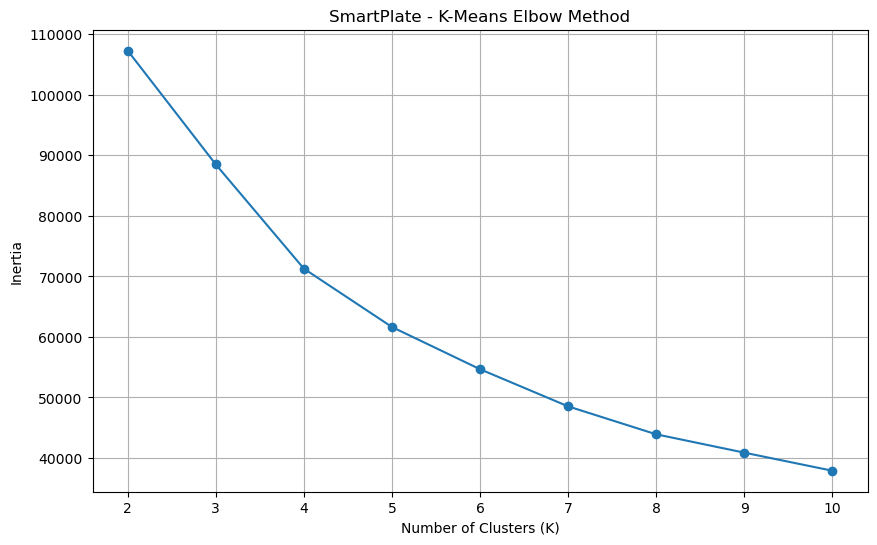

In [45]:
# ============================================================
# STEP 13: ELBOW GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.title("SmartPlate - K-Means Elbow Method")

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Inertia")

plt.xticks(range(2, 11))

plt.grid(True)

# Save graph as PNG
plt.savefig(
    "SmartPlate_KMeans_Elbow_Graph.png",
    dpi=300,
    bbox_inches="tight"
)



In [46]:
# ============================================================
# STEP 14: CREATE K-MEANS MODEL
# ============================================================

K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

print("✅ K-Means model created")
print("Number of Clusters:", K)

✅ K-Means model created
Number of Clusters: 3


In [47]:
# ============================================================
# STEP 15: APPLY K-MEANS
# ============================================================

clusters = kmeans.fit_predict(X_scaled)

print("✅ K-Means clustering completed")

✅ K-Means clustering completed


In [48]:
# ============================================================
# STEP 16: ADD CLUSTER COLUMN
# ============================================================

df["Cluster"] = clusters

print("Dataset with Cluster:")

display(
    df[features + ["Cluster"]].head(10)
)

Dataset with Cluster:


,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,Temperature,Estimated_Cost_of_Waste,Unmet_Demand,Cluster
0,41.07,39.09,1.98,39.09,171.55,21.2,1.58,0.00,1
1,41.47,40.10,1.37,40.10,171.55,21.2,1.09,0.00,1
2,40.15,37.21,2.94,37.21,171.55,21.2,2.94,0.00,1
3,77.84,57.53,20.31,57.53,171.55,21.2,10.15,0.00,1
4,40.98,39.88,1.10,39.88,171.55,21.2,3.31,0.00,1
5,106.36,106.36,0.00,116.79,171.55,21.2,0.00,10.43,1
6,67.33,63.87,3.46,63.87,171.55,21.2,10.39,0.00,1
7,41.27,40.29,0.98,40.29,171.55,21.2,3.91,0.00,1
8,61.00,56.50,4.50,56.50,171.55,21.2,11.24,0.00,1
9,42.51,41.98,0.53,41.98,171.55,21.2,1.06,0.00,1


In [49]:
# ============================================================
# STEP 17: CLUSTER DISTRIBUTION
# ============================================================

cluster_counts = (
    df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Number of Records in Each Cluster:")

display(cluster_counts)

Number of Records in Each Cluster:


Cluster
0    8827
1    9862
2    3211
Name: count, dtype: int64

In [50]:
# ============================================================
# STEP 18: SILHOUETTE SCORE
# ============================================================

silhouette = silhouette_score(
    X_scaled,
    clusters
)

print(
    f"Silhouette Score: {silhouette:.4f}"
)

Silhouette Score: 0.3257


In [51]:
# ============================================================
# STEP 19: CLUSTER SUMMARY
# ============================================================

cluster_summary = (
    df.groupby("Cluster")[features]
    .mean()
)

print("Cluster Characteristics:")

display(
    cluster_summary.round(2)
)

Cluster Characteristics:


,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,Temperature,Estimated_Cost_of_Waste,Unmet_Demand
Cluster,,,,,,,,
0,323.31,304.82,18.48,308.36,918.03,25.97,30.51,3.54
1,79.91,74.73,5.18,75.28,310.71,27.31,8.30,0.56
2,627.35,572.25,55.11,572.50,1019.50,25.51,80.28,0.25


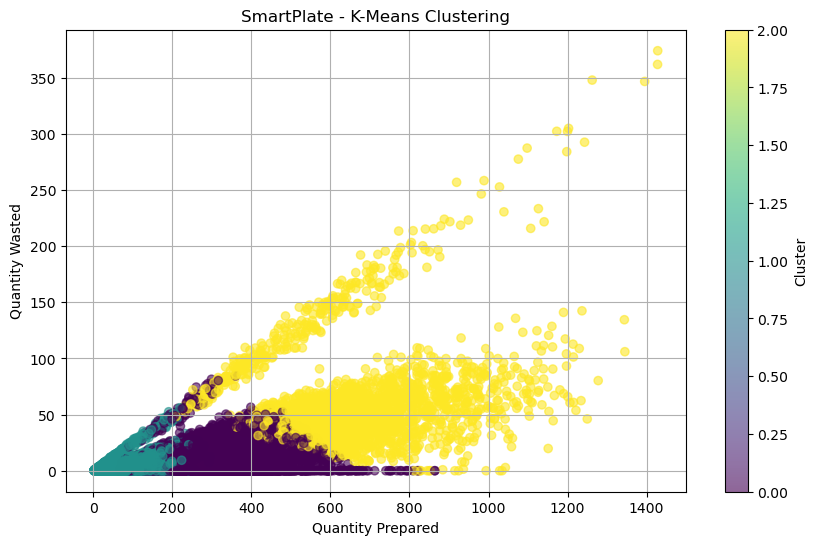

In [56]:
# ============================================================
# STEP 20: CLUSTER VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["Quantity_Prepared"],
    df["Quantity_Wasted"],
    c=df["Cluster"],
    alpha=0.6
)

plt.title("SmartPlate - K-Means Clustering")
plt.xlabel("Quantity Prepared")
plt.ylabel("Quantity Wasted")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.grid(True)

# Save graph as PNG
plt.savefig(
    "SmartPlate_KMeans_Clustering.png",
    dpi=300,
    bbox_inches="tight"
)



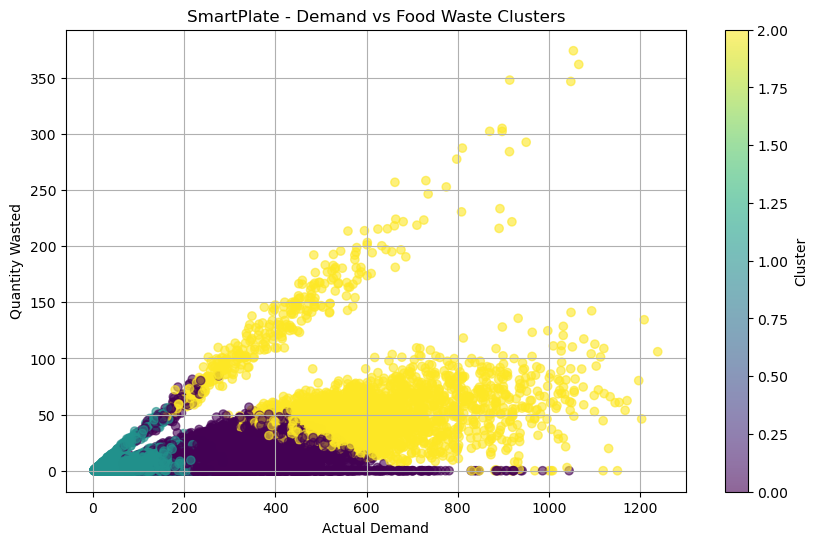

In [53]:
# ============================================================
# STEP 21: DEMAND VS WASTE
# ============================================================

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["Actual_Demand"],
    df["Quantity_Wasted"],
    c=df["Cluster"],
    alpha=0.6
)

plt.title(
    "SmartPlate - Demand vs Food Waste Clusters"
)

plt.xlabel(
    "Actual Demand"
)

plt.ylabel(
    "Quantity Wasted"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.grid(True)

# Save graph as PNG
plt.savefig(
    "SmartPlate_Demand_vs_Waste_Clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
# ============================================================
# STEP 22: SAVE K-MEANS RESULT
# ============================================================

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("✅ K-Means results saved successfully")

print("Output File:")
print(OUTPUT_FILE)

✅ K-Means results saved successfully
Output File:
C:\Users\Aaditya babaso patil\Desktop\SmartPlate_Data_Mining_Project\data\smartplate_kmeans_clusters.csv


In [55]:
# ============================================================
# STEP 23: FINAL RESULT
# ============================================================

print("=" * 70)
print("SMARTPLATE K-MEANS CLUSTERING COMPLETED")
print("=" * 70)

print("Total Records:", len(df))

print("Number of Clusters:", K)

print(
    f"Silhouette Score: {silhouette:.4f}"
)

print("\nCluster Distribution:")

print(cluster_counts)

print("\n✅ K-Means clustering completed successfully.")
print("✅ Results saved to CSV file.")

SMARTPLATE K-MEANS CLUSTERING COMPLETED
Total Records: 21900
Number of Clusters: 3
Silhouette Score: 0.3257

Cluster Distribution:
Cluster
0    8827
1    9862
2    3211
Name: count, dtype: int64

✅ K-Means clustering completed successfully.
✅ Results saved to CSV file.
